# Measurement-induced phase transition: a tour

A quantum computer that is left alone spreads entanglement through its qubits. Measuring qubits does the opposite: each measurement collapses a qubit and cuts it out of the web of correlations. In a circuit that does both, random gates and random measurements, the competition between the two produces a sharp **phase transition** as the measurement rate *p* is tuned: the *measurement-induced phase transition* (MIPT). For background, see the review by [Fisher, Khemani, Nahum & Vijay, arXiv:2207.14280](https://arxiv.org/abs/2207.14280) (Annu. Rev. Condens. Matter Phys. 14, 335 (2023)).

This notebook shows:

1. the circuits we sample,
2. the half-chain entanglement entropy across the transition (**area law versus volume law**),
3. **entanglement-weighted graphs** ([Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969)): which measurement patterns in spacetime produce entanglement between two distant pairs of qubits,
4. how entanglement between distant regions decays at the critical point, from the same paper.

All simulations use `mipt_sim`, a dense state-vector simulator in NumPy. Heavy runs are done by the scripts in `scripts/` and loaded here from `results/`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import MaxNLocator

from mipt_sim import half_chain_entropy, random_circuit, run_circuit
from mipt_sim.ewg import weighted_graph

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 1. The circuit

A ring of *L* qubits starts in $|00\cdots0\rangle$. Each time step has two parts:

- **Gates.** Two-qubit gates act on neighbouring pairs in a brickwork pattern: pairs (0,1), (2,3), … on even steps and (1,2), (3,4), …, (L−1, 0) on odd steps. The chain is **periodic**, so the last qubit couples back to the first. Each gate is an independent random unitary drawn from the [Haar measure](https://en.wikipedia.org/wiki/Haar_measure) on U(4), the "most random" two-qubit gate.
- **Measurements.** Each qubit is then measured in the computational basis with probability *p*. The outcome is random, drawn with the Born rule, and the state collapses accordingly.

One such random circuit, with its random measurement locations, is a *circuit realization*. Running it once, with random measurement outcomes, is a *trajectory*. Below is one realization for L = 6 over four time steps, drawn with PennyLane's `qml.draw_mpl` (wires are labelled from 0 here). The tall box spanning all wires is the gate that closes the ring on qubits 5 and 0: it acts only on those two, at the tabs.

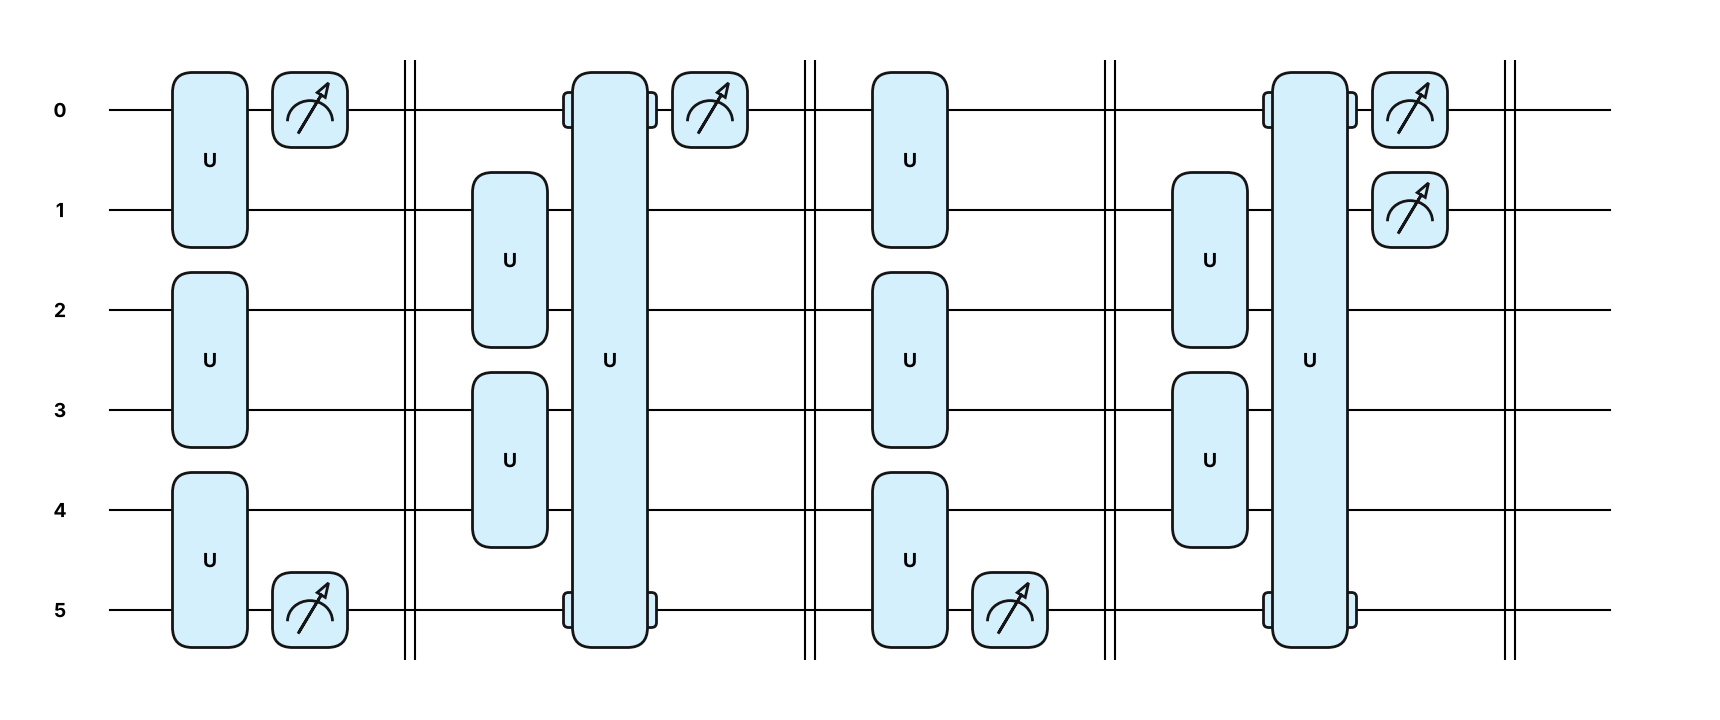

In [2]:
import pennylane as qml

L_demo = 6
layers = random_circuit(L_demo, 0.25, np.random.default_rng(3), depth=4)


def demo_circuit():
    for gates, measured in layers:
        for wires, u in gates:
            qml.QubitUnitary(u, wires=wires)
        for q in measured:
            qml.measure(q)
        qml.Barrier(wires=range(L_demo), only_visual=True)


fig, ax = qml.draw_mpl(demo_circuit, wire_order=range(L_demo), style="pennylane")()

## 2. Area law versus volume law

Cut the ring into two halves and ask how entangled they are. The [von Neumann entropy](https://en.wikipedia.org/wiki/Von_Neumann_entropy) *S* of one half counts this in bits: a product state has *S* = 0, and a maximally entangled half of *L*/2 qubits has *S* = *L*/2.

- With **few measurements**, the gates win: *S* grows in proportion to the size of the half, a **volume law**.
- With **many measurements**, the measurements win: *S* stays bounded however large the system, an **area law** (in one dimension the "area" of a cut is just its two end points).

For random Haar gates on qubits, the transition sits near $p_c \approx 0.17$ ([Zabalo et al., arXiv:1911.00008](https://arxiv.org/abs/1911.00008), Phys. Rev. B 101, 060301 (2020)). First, two single trajectories at L = 14: the entropy grows from zero and saturates within a few time steps, at very different levels.

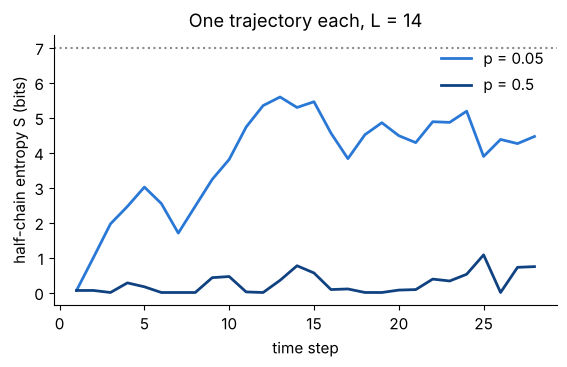

In [3]:
L, depth = 14, 28
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for p, c in [(0.05, "#2a78d6"), (0.5, "#104281")]:
    rng = np.random.default_rng(1)
    _, s = run_circuit(L, random_circuit(L, p, rng, depth), rng, record=True)
    ax.plot(range(1, depth + 1), s, color=c, lw=2, label=f"p = {p}")
ax.axhline(L / 2, ls=":", color="#8a8a86")
ax.set(xlabel="time step", ylabel="half-chain entropy S (bits)", title=f"One trajectory each, L = {L}")
ax.legend(frameon=False);

Averaging many trajectories for several sizes and rates (`scripts/sweep.py`, 40 to 800 trajectories per point, depth 2L) gives the main result. The entropy is also averaged over two neighbouring cut positions, because at large *p* it depends on whether the last layer of gates crossed the cut.

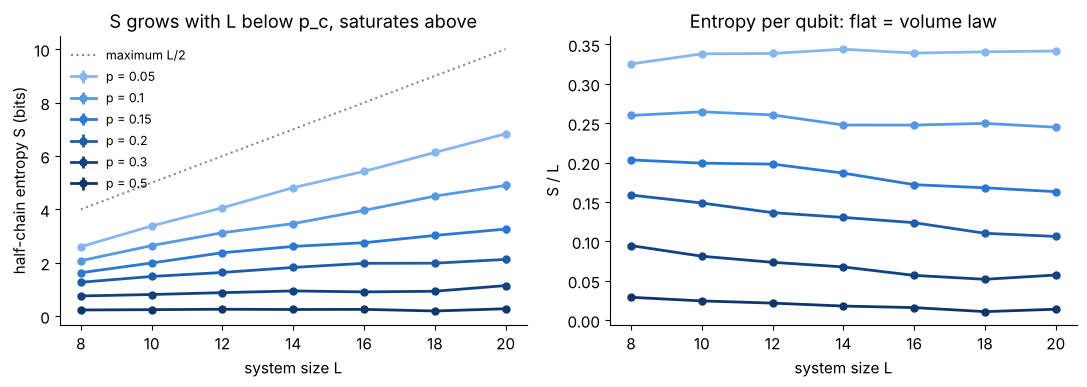

In [4]:
rows = json.load(open("../results/sweep.json"))
ps = sorted({r["p"] for r in rows})
blues = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]  # light = few measurements

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
Ls = sorted({r["L"] for r in rows})
a.plot(Ls, [x / 2 for x in Ls], ls=":", color="#8a8a86", label="maximum L/2")
for p, c in zip(ps, blues):
    d = sorted((r for r in rows if r["p"] == p), key=lambda r: r["L"])
    x, y, e = [r["L"] for r in d], [r["mean"] for r in d], [r["sem"] for r in d]
    a.errorbar(x, y, e, color=c, lw=2, marker="o", ms=5, label=f"p = {p:g}")
    b.plot(x, np.array(y) / np.array(x), color=c, lw=2, marker="o", ms=5)
a.set(xlabel="system size L", ylabel="half-chain entropy S (bits)", title="S grows with L below p_c, saturates above")
b.set(xlabel="system size L", ylabel="S / L", title="Entropy per qubit: flat = volume law")
a.legend(frameon=False, fontsize=9)
plt.tight_layout();

At *p* = 0.05 and 0.1 the entropy grows linearly with *L* (constant *S*/*L*): volume law. At *p* = 0.3 and 0.5 it is flat: area law. At *p* = 0.15 and 0.2, close to $p_c \approx 0.17$, it grows slowly, as expected near the critical point, where *S* grows like log *L*. Locating $p_c$ precisely needs larger sizes and a finite-size scaling analysis.

## 3. Entanglement-weighted graphs

At the critical point, two distant regions are *usually* not entangled at all. When they are, it is because the random measurements happened to fall in a favourable pattern. An **entanglement-weighted graph** (EWG) ([Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969), Sec. III B) shows that pattern on average. For every trajectory $\varepsilon$ we keep its measurement record $W_\varepsilon(x, t)$, equal to 1 if qubit *x* was measured at time *t* and 0 otherwise, and the entanglement $E(\varepsilon)$ it produced between regions *A* and *B* at the end. The graph is the entanglement-weighted average of the records,

$$
W[E](x, t) = \frac{\sum_\varepsilon E(\varepsilon)\, W_\varepsilon(x, t)}{\sum_\varepsilon E(\varepsilon)} .
$$

Where the measurements do not matter, this equals the bare rate *p* (white). Blue marks places measured *less* often than usual in the circuits that produced entanglement; red marks places measured *more* often.

Here L = 18 and p = 0.17. The regions are the pairs *A* = qubits (1, 2) and *B* = qubits (8, 9), counting from 1. The weight *E* is the [negativity](https://en.wikipedia.org/wiki/Negativity_(quantum_mechanics)) between *A* and *B*, computed with `medt`. The plot shows the last 20 of the 36 time steps; earlier steps sit at *p* within noise. The 20,000 trajectories come from `scripts/ewg_run.py`, which stores every measurement record and its seed, so any trajectory can be replayed.

In [5]:
d = np.load("../results/ewg_L18_p0.17.npz")
rec, p, L = d["records"], float(d["p"]), int(d["L"])
A, B = list(d["A"]), list(d["B"])
neg = d["negativity"]
print(f"{len(neg)} trajectories; negativity > 0 in {(neg > 1e-10).sum()} of them ({(neg > 1e-10).mean():.1%})")
print(f"mean negativity {neg.mean():.2e}")

20000 trajectories; negativity > 0 in 1181 of them (5.9%)
mean negativity 8.00e-04


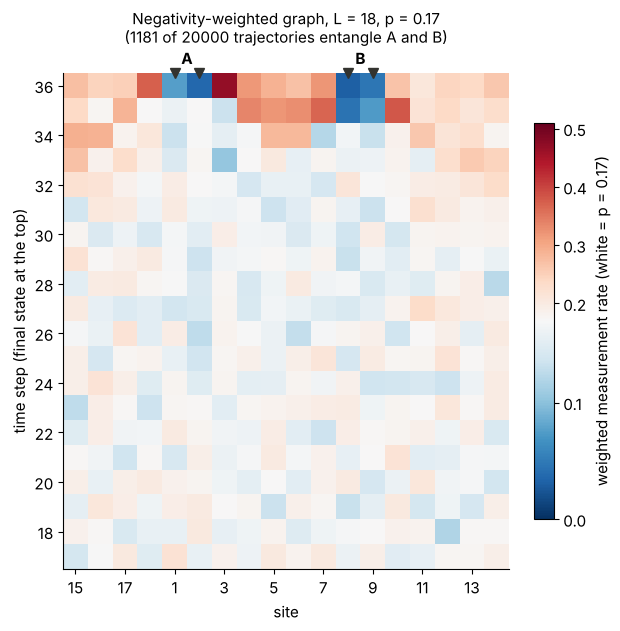

In [6]:
def plot_ewg(d, layers=20, ax=None):
    rec, p, L = d["records"], float(d["p"]), int(d["L"])
    A, B = list(d["A"]), list(d["B"])
    g = weighted_graph(rec, d["negativity"])[-layers:]
    t0 = len(rec[0]) - layers  # time steps shown: t0 + 1 ... depth
    shift = (L - 1 - A[0] - B[-1]) // 2  # roll the ring so A and B sit in the middle
    cols = (np.arange(L) - shift) % L
    if ax is None:
        _, ax = plt.subplots(figsize=(6.2, 6.2), constrained_layout=True)
    norm = TwoSlopeNorm(vcenter=p, vmin=0.0, vmax=3 * p)  # values above 3p saturate
    im = ax.imshow(
        np.roll(g, shift, axis=1),
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        aspect="equal",
        extent=(0.5, L + 0.5, t0 + 0.5, t0 + layers + 0.5),
    )
    ax.set_xticks(range(1, L + 1, 2), [str(cols[i] + 1) for i in range(0, L, 2)])
    ax.set_xlabel("site")
    ax.set_ylabel("time step (final state at the top)")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    top = t0 + layers + 0.5
    for q, lab in [(A, "A"), (B, "B")]:
        q = [(x + shift) % L for x in q]
        ax.annotate(
            lab,
            ((q[0] + q[-1]) / 2 + 1, top),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontweight="bold",
            annotation_clip=False,
        )
        for x in q:
            ax.plot([x + 1], [top], marker="v", color="#33332f", ms=7, clip_on=False)
    ax.set_xlim(0.5, L + 0.5)
    ax.set_ylim(t0 + 0.5, top)
    n_neg = int((d["negativity"] > 1e-10).sum())
    ax.set_title(
        f"Negativity-weighted graph, L = {L}, p = {p:g}\n({n_neg} of {len(rec)} trajectories entangle A and B)",
        pad=22,
        fontsize=11,
    )
    plt.colorbar(im, ax=ax, shrink=0.8, label=f"weighted measurement rate (white = p = {p:g})")
    return ax


plot_ewg(d, layers=20);

What the 20,000 trajectories show (about 1,200 of them have nonzero negativity; a bootstrap gives an uncertainty of about ±0.03 per cell in the top rows):

- **A and B themselves are rarely measured at the end** (rate about 0.05 against p = 0.17 in the last layer). That is expected: measuring a qubit of A or B just before the end destroys its entanglement.
- **The qubits between A and B are measured *more* often in the last two layers**, about 0.3 against 0.17, up to 0.47 for the qubit next to A. The neighbours of A and B on the far side (sites 18 and 10) are also enhanced. A plausible reading is **entanglement swapping**: measuring the qubits that mediate the correlation can transfer their entanglement onto A and B, and measuring the neighbours cuts A and B off from the rest of the chain. This red "halo" echoes the measurement halo in the paper.
- **Deeper in the past the graph returns to p** within noise. The memory of the measurement pattern reaches back only about three time steps here.

Unlike the paper's Fig. 6, we do not see a clear low-measurement bulk joining A and B. Possible reasons are the different gate set (Haar here, Mølmer–Sørensen in the paper), the small size, and the short separation; separating these would need larger *L* or more distances.

## 4. How entanglement decays with distance

The figure below is Fig. 4 of [Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969). It shows, at the critical point, how correlations between *k* distant regions fall off with their separation *d*: (a) the multiparty mutual information, which counts all correlations, and (b) the genuine multiparty negativity, which counts only genuine *k*-party entanglement. Both decay as power laws, a hallmark of criticality, and entanglement decays much faster than total correlation: for two parties, about $d^{-8.8}$ against $d^{-3.9}$. That steep decay is why the negativity above was zero in most trajectories.

One difference to keep in mind: the paper uses a trapped-ion gate set ([Mølmer–Sørensen](https://en.wikipedia.org/wiki/M%C3%B8lmer%E2%80%93S%C3%B8rensen_gate) gates dressed with random single-qubit rotations) rather than Haar-random gates. Both have their transition near *p* = 0.17.

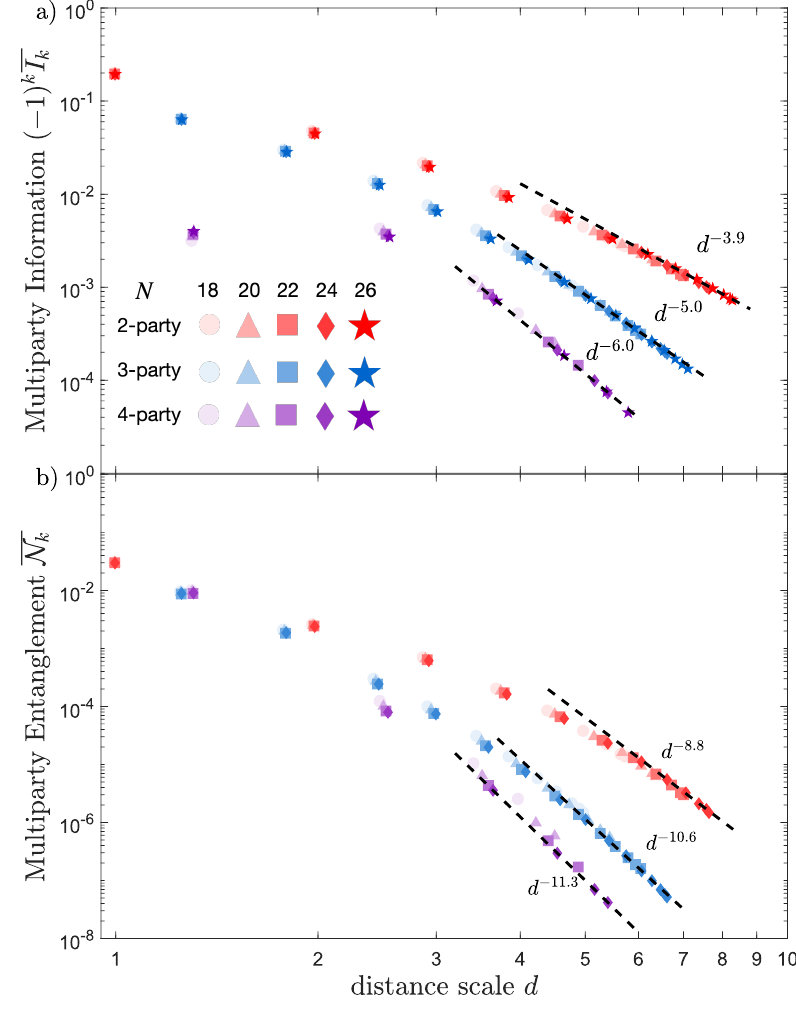

In [7]:
Image("figures/fig4_arXiv2602.04969.png", width=560)

## Notes

- **Simulator.** `mipt_sim.numpy_sim` stores the state as a `(2,)*L` tensor and applies each gate with one `np.tensordot`. A trajectory at L = 20 takes about 2.5 s on one core of a laptop-class CPU.
- **PennyLane.** Besides drawing the circuit, PennyLane checks the simulator: `mipt_sim.pennylane_check.circuit_qnode` builds the same monitored circuit with `qml.measure`, and the tests compare our trajectory averages with PennyLane's exact outcome-averaged values. PennyLane cannot run this study by itself, because in exact mode it never returns the post-measurement state of a single trajectory (see the README).